In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import itertools
import statsmodels.api as sm
import warnings
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import r2_score
from scipy.stats import boxcox
from scipy.special import inv_boxcox
warnings.filterwarnings("ignore")

In [19]:
series=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\time_series.csv",header=0,index_col=0,parse_dates=True).squeeze()
series.head()

Date
1967-01-01    25.5
1967-02-01    25.5
1967-03-01    25.5
1967-04-01    25.5
1967-05-01    25.5
Name: KCL, dtype: float64

In [20]:
series = series.asfreq('MS')

In [21]:
# Remplacer les infinis par NaN (si besoin)
series = series.replace([np.inf, -np.inf], np.nan)

In [22]:
data=series.dropna()

In [23]:
#test de stationnarité
result=adfuller(data)
print("ADF Statistic:",result[0])
print("p-value:",result[1])
# interpretation
if result[1] < 0.05:
    print("La série est stationnaire")
else:
    print("La série n'est pas stationnaire")

ADF Statistic: -2.07864399839044
p-value: 0.25318820316219454
La série n'est pas stationnaire


In [24]:
#partition des données (train/test)
train_size=int(len(data)*0.8)
train=data[:train_size]
test=data[train_size:]
print("Train size:",len(train))
print("test size:",len(test))

Train size: 565
test size: 142


In [25]:
#transformaton box cox
# train_boxcox, lam = boxcox(train)

# train_boxcox = pd.Series(train_boxcox,index=train.index)

train_log=np.log(train)
print(train_log.head())

Date
1967-01-01    3.238678
1967-02-01    3.238678
1967-03-01    3.238678
1967-04-01    3.238678
1967-05-01    3.238678
Name: KCL, dtype: float64


In [26]:
#test adf apres box cox
result_log = adfuller(train_log)

print("\n adf apres box cox")
print("ADF Statistic :", result_log[0])
print("p-value :", result_log[1])

if result_log[1] < 0.05:
    print("La série Box-Cox est stationnaire.")
else:
    print("La série Box-Cox n'est pas stationnaire.")


 adf apres box cox
ADF Statistic : -0.8977301799335484
p-value : 0.7887189829212851
La série Box-Cox n'est pas stationnaire.


In [28]:
#recherche de d
from pmdarima.arima import ndiffs

d_optimal = ndiffs(train_log)

print("Nombre de différenciations :", d_optimal)

Nombre de différenciations : 1


In [29]:
#validation temporelle
validation_size=12
train_arima=train_log.iloc[:-validation_size]#jusqu'a les 12 derniers
valid_arima = train_log.iloc[-validation_size:]#les 12 derniers



In [30]:
warnings.filterwarnings("ignore")

p = range(0, 6)
q = range(0, 6)
d = 1

results = []

#l ensemble de validation sur le train original
valid_original = train.iloc[-validation_size:]


for order in itertools.product(p, [d], q):

    try:
        model = ARIMA(
            train_arima,
            order=order
        )

        fitted = model.fit()

        # Prévision sur la période de validation
        pred_log= fitted.forecast(
            steps=len(valid_arima)
        )

        #retour a l echelle original

        pred=np.exp(pred_log)

        rmse = np.sqrt(
            mean_squared_error(
                valid_original,
                pred
            )
        )

        results.append({
            "Order": order,
            "RMSE_validation": rmse,
            "AIC": fitted.aic,
            "BIC": fitted.bic
        })

    except:
        continue


results = pd.DataFrame(results)


# classement par RMSE (objectif prédiction)
results = results.sort_values(
    by="RMSE_validation"
)


print("Meilleurs modèles ARIMA :")
print(results.head(10))


best_order = results.iloc[0]["Order"]

print("\nMeilleur ordre ARIMA :", best_order)

Meilleurs modèles ARIMA :
        Order  RMSE_validation          AIC          BIC
0   (0, 1, 0)     5.684342e-14 -1416.130834 -1411.817286
3   (0, 1, 3)     2.381998e+00 -1416.921526 -1399.667334
4   (0, 1, 4)     2.505363e+00 -1415.257848 -1393.690108
18  (3, 1, 0)     2.552684e+00 -1416.853435 -1399.599243
5   (0, 1, 5)     2.756583e+00 -1413.309808 -1387.428520
24  (4, 1, 0)     2.863045e+00 -1415.634469 -1394.066729
25  (4, 1, 1)     2.927856e+00 -1413.652459 -1387.771171
14  (2, 1, 2)     2.931914e+00 -1419.990413 -1398.422673
30  (5, 1, 0)     3.075355e+00 -1413.656967 -1387.775679
13  (2, 1, 1)     3.810631e+00 -1418.859826 -1401.605634

Meilleur ordre ARIMA : (0, 1, 0)


In [31]:
model = ARIMA(train_log, order=best_order)

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    KCL   No. Observations:                  565
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 730.545
Date:                Thu, 13 Aug 2026   AIC                          -1459.089
Time:                        13:06:25   BIC                          -1454.754
Sample:                    01-01-1967   HQIC                         -1457.397
                         - 01-01-2014                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0044   6.15e-05     71.351      0.000       0.004       0.005
Ljung-Box (L1) (Q):                   5.70   Jarque-Bera (JB):             27471.04
Prob(Q):                              0.02   Pr

In [32]:
#autocorrelation

#diagnostic des residus
from statsmodels.stats.diagnostic import acorr_ljungbox

residuals = model_fit.resid.dropna() 

# Test de Ljung-Box
lb_test = acorr_ljungbox(
    residuals,
    lags=[12],
    return_df=True
)

print("\nTest de Ljung-Box :")
print(lb_test)


Test de Ljung-Box :
    lb_stat  lb_pvalue
12  0.86534   0.999994


In [34]:
forecast_log = model_fit.forecast(
    steps=len(test)
)


#retour a l echelle
forecast = np.exp(forecast_log)

In [35]:
print("NaN dans test :", test.isna().sum())
print("NaN dans forecast :", np.isnan(forecast).sum())

print(forecast[:10])

NaN dans test : 0
NaN dans forecast : 0
2014-02-01    395.0
2014-03-01    395.0
2014-04-01    395.0
2014-05-01    395.0
2014-06-01    395.0
2014-07-01    395.0
2014-08-01    395.0
2014-09-01    395.0
2014-10-01    395.0
2014-11-01    395.0
Freq: MS, Name: predicted_mean, dtype: float64


In [36]:
mae = mean_absolute_error(test, forecast)

mse = mean_squared_error(test, forecast)

rmse = np.sqrt(mse)

mape = mean_absolute_percentage_error(test, forecast)

r2 = r2_score(test, forecast)


print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print(f"MAPE : {mape*100:.2f}%")
print("R² :", r2)

MAE : 157.48411971830987
MSE : 42340.608394894385
RMSE : 205.7683367160613
MAPE : 47.24%
R² : -0.04766151940226071


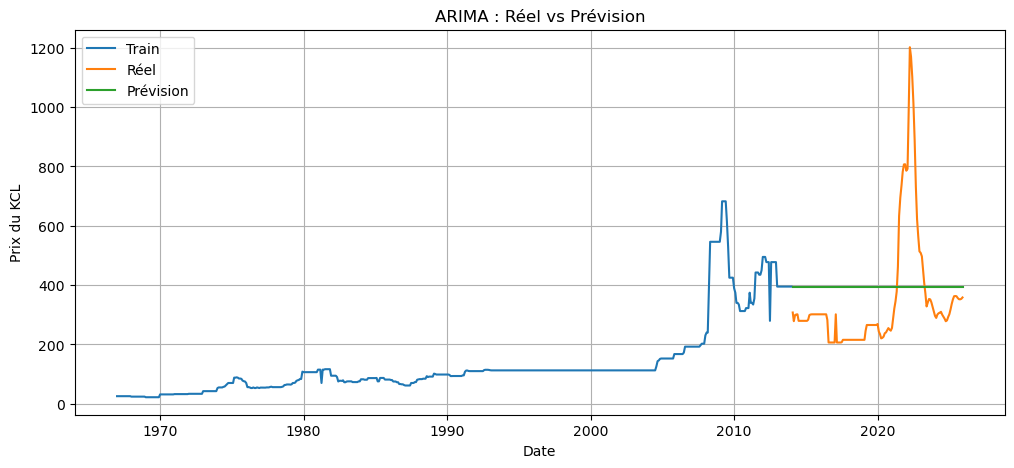

In [94]:
plt.figure(figsize=(12,5))

plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Réel")
plt.plot(test.index,forecast, label="Prévision")

plt.title("ARIMA : Réel vs Prévision")

plt.xlabel("Date")
plt.ylabel("Prix du KCL")

plt.legend()
plt.grid(True)

plt.show()

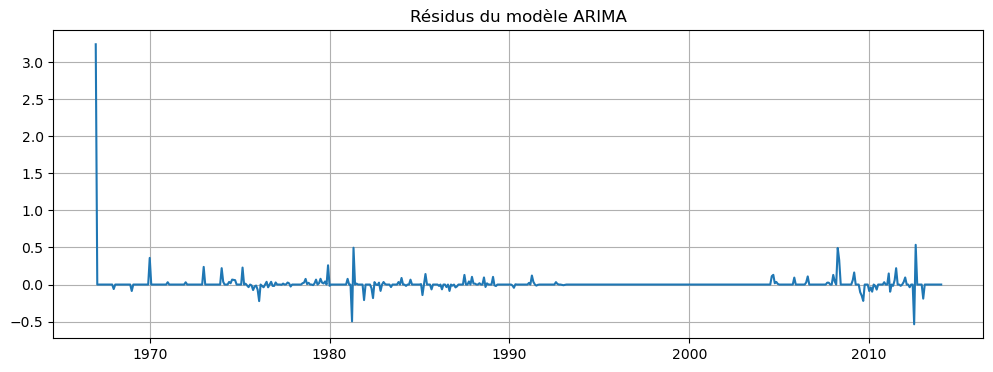

In [95]:
#Analyse des résidus
residuals = model_fit.resid

plt.figure(figsize=(12,4))

plt.plot(residuals)

plt.title("Résidus du modèle ARIMA")

plt.grid(True)

plt.show()


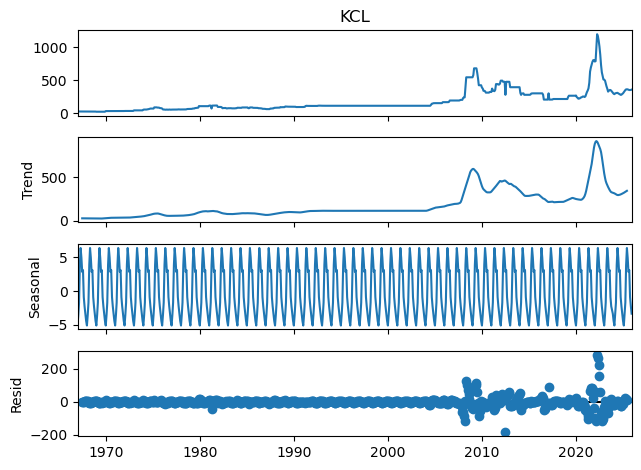

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomp = seasonal_decompose(data, model='additive', period=12)
decomp.plot()
plt.show()
#composante saisonniere annuelle tres faible

<Figure size 1200x500 with 0 Axes>

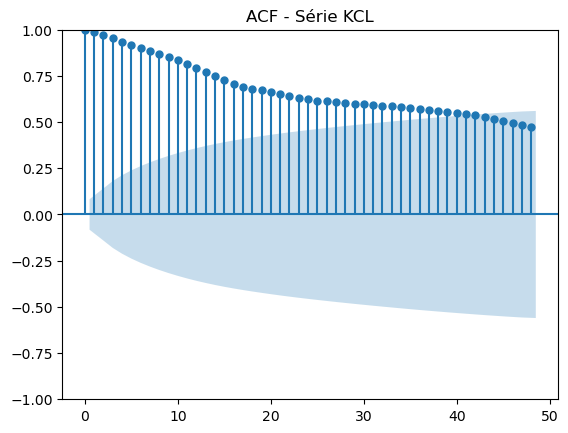

In [97]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(
    train,
    lags=48,
    alpha=0.05
)

plt.title("ACF - Série KCL")
plt.show()